# Setup

In [1]:
# Standard library imports
from html import escape
from pathlib import Path
import re
import textwrap

# Third-party imports: data, plotting, and notebook display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import to_rgba
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Markdown, HTML

# Forecasting tools and reporting workflow
from agentic_ts.forecasting import (
    CATALOG, FOLD_ENDS, load_panel, split_series, fit_forecast,
    evaluate_forecast, run_experiment, build_evidence, results_table,
)
from agentic_ts.workflow import (
    ModelConfig, load_capture, render_report, report_markdown, inject_unknown_reference,
)

This code imports libraries used for time series forecasting, data manipulation, visualization, and reporting within a Jupyter notebook environment. 

The first section imports standard Python modules: `html` for escaping HTML characters, `pathlib` for file path handling, `re` for regular expressions, and `textwrap` for text formatting.

Next, it imports core scientific computing libraries: `numpy` for numerical operations, `pandas` for data analysis with DataFrames, and `matplotlib` for plotting. Specific modules from `matplotlib` are imported to customize plot appearance—handling dates (`mdates`), color manipulation (`to_rgba`), and creating custom shapes (`FancyBboxPatch`, `FancyArrowPatch`).  The `IPython.display` module is used to render rich output (Markdown, HTML) directly within a notebook.

Finally, the code imports modules from a package named `agentic_ts`. This package provides functionality for:
*   **Forecasting:** Loading time series data (`load_panel`), splitting it into training and testing sets (`split_series`), fitting forecasting models (`fit_forecast`), evaluating their performance (`evaluate_forecast`), running experiments (`run_experiment`), and building evidence/results (`build_evidence`, `results_table`). A `CATALOG` variable and `FOLD_ENDS` are also imported, suggesting a structured approach to data organization and cross-validation.
*   **Workflow:** Managing model configurations (`ModelConfig`), loading captured data (`load_capture`), rendering reports (`render_report`), generating report content in Markdown format (`report_markdown`), and handling unknown references within the reporting process (`inject_unknown_reference`).

In [2]:
# General settings
class CFG:
    root = Path.cwd()
    data_folder = root / "data" / "a01"
    graph_folder = root / "graphs"
    capture_file = root / "examples" / "a01" / "recorded_run.json"
    run_mode = "replay"  # change to "live" for three local model requests
    SEED = 42

    # Display and publication exports
    plot_style = "seaborn-v0_8"
    img_dim1 = 20
    img_dim2 = 10
    export_dpi = 180
    asset_prefix = "atsf01"
    table_decimals = 2
    short_industries = ["Groceries", "Clothing", "Hardware / garden", "Cafés / restaurants"]
    short_states = {
        "New South Wales": "NSW", "Victoria": "VIC",
        "Queensland": "QLD", "Western Australia": "WA",
    }

    # Local LLM backend and generation settings
    llm = ModelConfig(
        model="qwen3-coder-next:q4_K_M",
        base_url="http://localhost:11434",
        temperature=0.0,
        seed=SEED,
        num_ctx=32768,
        num_predict=4096,
        timeout_seconds=240.0,
    )


# Display style and reproducibility
plt.style.use(CFG.plot_style)
plt.rcParams["figure.figsize"] = (CFG.img_dim1, CFG.img_dim2)
np.random.seed(CFG.SEED)
pd.options.display.float_format = f"{{:.{CFG.table_decimals}f}}".format

assert (CFG.data_folder / "manifest.json").exists(), "Run from the repository root"
CFG.graph_folder.mkdir(exist_ok=True)
print(f"Reporting mode: {CFG.run_mode}; local model: {CFG.llm.model}")

Reporting mode: replay; local model: qwen3-coder-next:q4_K_M


This defines a configuration class, `CFG`, to store settings for a time series forecasting workflow. It establishes paths, parameters for data loading and visualization, and configurations for a local Large Language Model (LLM) backend.

First, it sets file system paths:
*   `root`: The current working directory.
*   `data_folder`: A subdirectory within `root` named "data/a01" where the time series data is located.
*   `graph_folder`:  A subdirectory for storing generated plots and visualizations.
*   `capture_file`: Specifies a JSON file ("recorded_run.json") containing potentially pre-computed results or a record of a previous run, found within "examples/a01".

The `run_mode` variable determines whether the workflow operates in “replay” mode (using data from `capture_file`) or “live” mode (making requests to local models).  A `SEED` is set for reproducibility.

Next, it defines settings related to display and output:
*   `plot_style`: Sets the Matplotlib plot style to "seaborn-v0_8".
*   `img_dim1`, `img_dim2`: Define the dimensions of generated plots in inches.
*   `export_dpi`:  Sets the resolution for exported images to 180 DPI.
*   `asset_prefix`: A prefix used when naming output files (e.g., image filenames).
*   `table_decimals`: Specifies the number of decimal places to display in Pandas DataFrames.
*   `short_industries`, `short_states`: Dictionaries for abbreviating industry names and state names, likely for use in report generation or plot labels.

The code then configures a local LLM using a `ModelConfig` object:
*   `model`: Specifies the model to use ("qwen3-coder-next:q4_K_M"). This suggests a quantized version of the Qwen3 coder model is being used.
*   `base_url`:  The URL where the LLM server is running (http://localhost:11434).
*   `temperature`, `seed`, `num_ctx`, `num_predict`, `timeout_seconds`: Parameters controlling the LLM’s generation process—temperature for randomness, seed for reproducibility, context window size, maximum prediction length, and a timeout value.

Following configuration, it applies the specified plot style using `plt.style.use()`, sets the default figure size, seeds NumPy's random number generator, and configures Pandas to format floating-point numbers with the defined precision. 

An assertion verifies that a "manifest.json" file exists within the `data_folder` - the file is required for the workflow’s operation, and ensures the code is run from the correct directory (the repository root).

The `graph_folder` is created if it doesn't already exist. Finally, it prints the current reporting mode and the name of the local LLM model being used to the console.


# Utils

In [3]:
# Reset the export registry when running the notebook from the top.
exported_assets = []


def save_asset(fig, kind, number, title):
    filename = f"{CFG.asset_prefix}-{kind}{number}.png"
    if any(a["file"] == filename for a in exported_assets):
        raise ValueError(f"Duplicate asset number: {filename}; rerun from the first cell")
    fig.savefig(CFG.graph_folder / filename, dpi=CFG.export_dpi, bbox_inches="tight", facecolor="white")
    exported_assets.append({"kind": kind, "number": number, "title": title, "file": filename})
    display(Markdown(f"**{kind.title()} {number}: {title}** — `graphs/{filename}`"))

This code defines a function, `save_asset`, for saving Matplotlib figures as PNG images and tracking exported assets to prevent duplicates. 
The `exported_assets` list is initialized outside the function; it acts as a global registry to keep track of all saved image files during a single execution of the notebook. This ensures that if the notebook is run from beginning to end, images aren’t overwritten with the same filename.

The `save_asset` function takes four arguments:
*   `fig`: The Matplotlib figure object to be saved.
*   `kind`: A string describing the type of visualization (e.g., "forecast", "actual").
*   `number`: An integer representing the sequence number of this asset within its kind.
*   `title`: A descriptive title for the visualization.

Inside the function:
1.  A filename is constructed using `CFG.asset_prefix`, `kind`, `number`, and the ".png" extension. This ensures unique filenames based on the configuration settings.
2.  The code checks if a file with the same name already exists in the `exported_assets` list. If it does, a `ValueError` is raised, indicating that an asset number has been reused—suggesting the notebook wasn’t run from the first cell or there's a logic error in the asset numbering.
3.  If the filename is unique, the figure is saved to the `CFG.graph_folder` using `fig.savefig()`. The `dpi`, `bbox_inches`, and `facecolor` arguments control the image quality, ensure tight cropping, and set a white background respectively.
4.  Information about the saved asset (kind, number, title, filename) is appended to the `exported_assets` list for tracking.
5.  Finally, a Markdown string is created and displayed using `display(Markdown(...))`. This string provides a user-friendly link to the saved image within the notebook, showing its kind, number, title, and relative path in the "graphs" folder.

 It relies on the `CFG` object for configuration settings like the asset prefix and graph folder location.

In [4]:
def table_text(text):
    """Round decimal results for display; never modify the captured response."""
    return re.sub(r"(?<![\w.])-?\d+\.\d+(?!\w|\.\d)", lambda match: f"{float(match[0]):.{CFG.table_decimals}f}", str(text))


def save_table(frame, number, title, widths=None, show=False):
    """Export the complete table grid, with two decimals and no title or footer."""
    data = frame.copy()
    def value_text(value):
        if isinstance(value, (list, tuple)):
            return "; ".join(table_text(v) for v in value)
        if value is None or (isinstance(value, float) and not np.isfinite(value)):
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{CFG.table_decimals}f}"
        return table_text(value)
    values = [[value_text(v) for v in row] for row in data.itertuples(index=False, name=None)]
    headers = [str(c).replace("_", " ") for c in data.columns]
    if not values:
        values = [["No rows"] + [""] * (len(headers) - 1)]
    if widths is None:
        widths = [min(36, max(12, len(headers[j]), max(len(r[j]) for r in values))) for j in range(len(headers))]
    def wrap(value, width):
        return "\n".join(textwrap.fill(line, width=width, break_long_words=False, break_on_hyphens=False)
                         for line in value.split("\n"))
    wrapped = [[wrap(v, w) for v, w in zip(row, widths)] for row in [headers] + values]
    heights = [max(v.count("\n") + 1 for v in row) * .20 + .18 for row in wrapped]
    body_height = sum(heights)
    fig = plt.figure(figsize=(max(7, sum(widths) * .085), body_height + .04))
    ax = fig.add_axes([.01, .02 / (body_height + .04), .98, body_height / (body_height + .04)])
    ax.axis("off")
    artist = ax.table(cellText=wrapped, colWidths=np.array(widths) / sum(widths),
                      cellLoc="left", bbox=[0, 0, 1, 1])
    artist.auto_set_font_size(False)
    artist.set_fontsize(9)
    for (row, col), cell in artist.get_celld().items():
        cell.set_height(heights[row] / body_height)
        cell.PAD = .055
        cell.set_edgecolor("white")
        cell.set_facecolor("#15384a" if row == 0 else ("#edf3f5" if row % 2 else "white"))
        if row == 0:
            cell.get_text().set_color("white")
            cell.get_text().set_weight("bold")
    # Verify the rendered table itself, including values embedded in prose.
    assert not fig.texts and not ax.get_title()
    for cell in artist.get_celld().values():
        assert not re.search(rf"(?<![\w.])\d+\.\d{{{CFG.table_decimals + 1},}}(?!\w|\.\d)", cell.get_text().get_text())
    save_asset(fig, "table", number, title)
    if show:
        display(fig)
    plt.close(fig)

The function `save_table` that exports a Pandas DataFrame as a visually formatted table within a Matplotlib figure and saves it as a PNG image. It’s designed for inclusion in reports generated by the larger `agentic_ts` workflow.

The function takes several arguments:
*   `frame`: The Pandas DataFrame to be exported.
*   `number`: An integer representing the sequence number of this table asset.
*   `title`: A descriptive title for the table.
*   `widths`: Optional list of column widths; if None, they are calculated automatically.
*   `show`: Boolean flag indicating whether to display the Matplotlib figure in the notebook immediately after saving it.

The function first creates a copy of the input DataFrame (`data = frame.copy()`) to avoid modifying the original data. It then defines an inner function `value_text(value)` which handles formatting individual cell values:
*   Lists and tuples are joined into semicolon-separated strings.
*   `None` or non-finite floating-point numbers (NaN, inf) are replaced with "—".
*   Floating-point numbers are formatted to the number of decimal places specified in `CFG.table_decimals`.
*   Other values are passed through the `table_text` function (described below).

The `table_text` function itself is a helper that uses regular expressions to round floating point numbers within strings to the precision defined by `CFG.table_decimals`, but only if they aren't part of a larger word or number. It’s designed to ensure consistency in decimal representation throughout the report, without altering the original data source.

The code then converts the DataFrame into a list of lists (`values`) where each inner list represents a row and contains formatted string representations of the cell values using `value_text`.  Headers are extracted from the DataFrame's column names, replacing underscores with spaces for readability. If the DataFrame is empty, it creates a single-row table indicating "No rows".

Column widths are either provided as input or calculated automatically to fit the content and headers, with minimum and maximum width constraints. A `wrap` function is defined to handle long text within cells by wrapping it into multiple lines using `textwrap.fill`. The code then creates a wrapped version of the table data (`wrapped`) where each cell contains potentially multi-line text.

A Matplotlib figure is created with dimensions based on the calculated column widths and row heights. An axes object is added to the figure, occupying most of its area.  The `ax.table` function is used to create a Matplotlib table within the axes, using the wrapped data, specified column widths, and left alignment.

Customization is applied to the table’s appearance: font size, cell padding, edge colors, background colors (alternating rows), header styling (bold text, white color). Assertions are included to verify that no raw text or unformatted floating-point numbers remain in the rendered table cells. This ensures the formatting has been correctly applied.

Finally, the `save_asset` function (defined previously) is called to save the figure as a PNG image with appropriate filename and title. If `show` is True, the Matplotlib figure is displayed in the notebook using `display(fig)`, and then closed to free up memory.

In [5]:
def box(ax, x, y, w, h, text, color=None):
    """Draw a labeled workflow node on the supplied axes."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.10", facecolor=to_rgba("C0", .12) if color is None else color, edgecolor="C0"))
    ax.text(x+w/2, y+h/2, text, ha="center", va="center", fontsize=14, color="0.15")


def arrow(ax, start, end, dashed=False):
    """Connect workflow nodes on the supplied axes."""
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, color="0.4", linestyle="--" if dashed else "-"))

These two functions provide utilities for drawing labeled boxes and arrows to visually represent a workflow or diagram within a Matplotlib axes object. They are designed to create simple, stylized diagrams suitable for illustrating processes in reports or presentations.

The `box` function draws a rectangular box with rounded corners and a label inside it:
*   It takes the Matplotlib axes object (`ax`), coordinates for the top-left corner (`x`, `y`), width (`w`), height (`h`), text to display within the box, and an optional color.
*   A `FancyBboxPatch` is added to the axes, defining the rectangular shape with rounded corners using `boxstyle="round,pad=0.10"`. The fill color defaults to a light blue-gray ("C0" with alpha 0.12) if no color is provided; otherwise, it uses the specified color.  The edge color is set to "C0".
*   Text is added to the center of the box using `ax.text()`, horizontally and vertically aligned to the center (`ha="center", va="center"`), with a font size of 14 and a dark gray color ("0.15").

The `arrow` function draws an arrow connecting two points on the axes:
*   It takes the Matplotlib axes object (`ax`), starting coordinates (`start`), ending coordinates (`end`), and an optional boolean flag `dashed` to indicate whether the arrow should be dashed or solid.
*   A `FancyArrowPatch` is added to the axes, defining the arrow shape with a specific style (`arrowstyle="-|>"`) and mutation scale (adjusting the size of the arrowhead). The color is set to a medium gray ("0.4"), and the linestyle is set to dashed if `dashed` is True; otherwise, it’s solid.

These functions are building blocks for creating visual representations of workflows or processes directly within Matplotlib figures. They provide a simple way to add labeled nodes and connections to diagrams without requiring complex manual drawing operations.

# The dataset

In [6]:
panel, manifest = load_panel(CFG.data_folder)
panel_table = pd.DataFrame(manifest["series"])
display(panel_table)
save_table(panel_table, 1, "Australian retail panel: source series", widths=[12, 22, 50])
print(f"{len(panel):,} observations; {panel.series_id.nunique()} series; {manifest['units']}")
print("Source SHA-256:", manifest["source_sha256"])
print("CSV SHA-256:", manifest["csv_sha256"])

,series_id,state,industry
0,A3349335T,New South Wales,Supermarket and grocery stores
1,A3349399C,New South Wales,Clothing retailing
2,A3349337W,New South Wales,"Hardware, building and garden supplies retailing"
3,A3349709X,New South Wales,"Cafes, restaurants and catering services"
4,A3349565X,Victoria,Supermarket and grocery stores
5,A3349483V,Victoria,Clothing retailing
6,A3349416V,Victoria,"Hardware, building and garden supplies retailing"
7,A3349640L,Victoria,"Cafes, restaurants and catering services"
8,A3349882C,Queensland,Supermarket and grocery stores
9,A3349477X,Queensland,Clothing retailing


**Table 1: Australian retail panel: source series** — `graphs/atsf01-table1.png`

4,896 observations; 16 series; nominal AUD millions
Source SHA-256: 13853143285f65c1d368c51b81e9bf83aab1d9613dac1c091e0dd38e6c64ae5c
CSV SHA-256: 6822dd47bdbad769feb6238a7044d4474033bc970690034c4dd9d3bad2999c21


This code loads a time series dataset, displays its metadata in a Pandas DataFrame, saves that metadata as a formatted table image, and prints summary statistics about the data.

First, `load_panel(CFG.data_folder)` is called to load the time series data from the directory specified by `CFG.data_folder`. This function returns two values:
*   `panel`: Presumably an object containing the actual time series data (likely a Pandas DataFrame or similar structure).
*   `manifest`: A dictionary containing metadata about the dataset, such as information about the series and units.

The code then creates a Pandas DataFrame called `panel_table` from the "series" key within the `manifest` dictionary. This DataFrame likely represents a summary of the time series data—perhaps listing series IDs, descriptions, or other relevant attributes. The DataFrame is displayed in the Jupyter notebook using `display(panel_table)`.

Next, the `save_table` function (defined previously) is called to save the `panel_table` as a formatted image file. It’s given the number 1, the title "Australian retail panel: source series", and a list of column widths for better presentation. This creates an image of the metadata table in the `CFG.graph_folder`.

Finally, several summary statistics are printed to the console:
*   The total number of observations (data points) in the dataset, formatted with commas for readability.
*   The number of unique time series IDs within the panel.
*   The units of measurement used in the data, as specified in the `manifest` dictionary.
*   SHA-256 hashes for both the original source data and the CSV file from which it was loaded. These hashes are important for verifying data integrity and reproducibility.

**Graph 1: Development histories, January 2000–June 2024** — `graphs/atsf01-graph1.png`

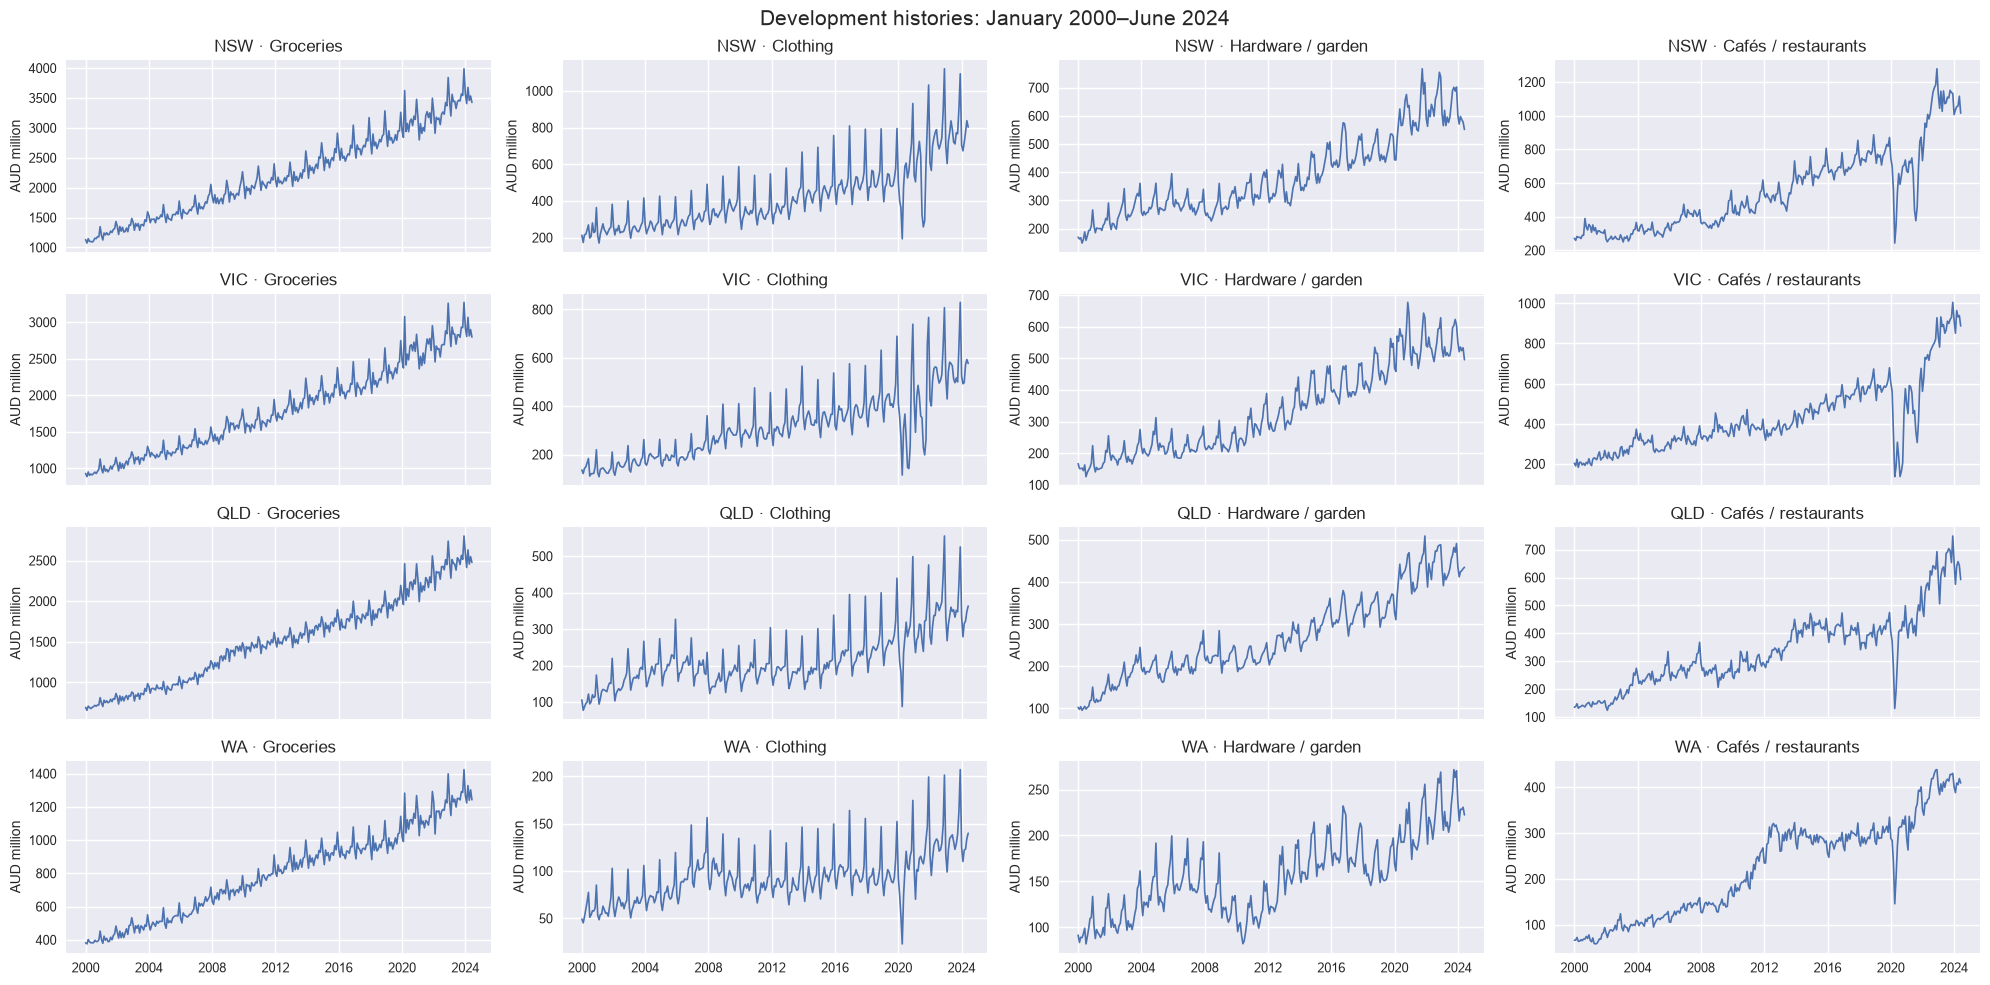

In [7]:
# Development histories only. Each panel has its own scale.
states = list(dict.fromkeys(panel.state))
industries = list(dict.fromkeys(panel.industry))
fig, axes = plt.subplots(4, 4, sharex=True)
for i, state in enumerate(states):
    for j, industry in enumerate(industries):
        ax = axes[i, j]
        part = panel[(panel.state == state) & (panel.industry == industry) & (panel.date <= "2024-06-01")]
        ax.plot(part.date, part.turnover_aud_millions, linewidth=1.2)
        ax.set_title(f"{CFG.short_states[state]} · {CFG.short_industries[j]}", fontsize=12)
        ax.set_ylabel("AUD million", fontsize=10)
        ax.tick_params(labelsize=9)
fig.suptitle("Development histories: January 2000–June 2024", fontsize=15)
fig.tight_layout()
save_asset(fig, "graph", 1, "Development histories, January 2000–June 2024")
plt.show()

This code generates a grid of time series plots showing the development of retail turnover for different combinations of Australian states and industries. First, it extracts unique lists of `state` and `industry` values from the `panel` DataFrame using `dict.fromkeys()` to preserve order while removing duplicates.

A 4x4 grid of subplots is created using `plt.subplots(4, 4, sharex=True)`. The `sharex=True` argument ensures that all subplots share the same x-axis (date).

The code then iterates through each combination of state and industry using nested loops:
*   For each combination, it filters the `panel` DataFrame to select data for that specific state, industry, and dates up to "2024-06-01". This filtered subset is stored in the `part` variable.
*   The code then plots the time series of `turnover_aud_millions` against `date` on the corresponding subplot (`ax`). The line width is set to 1.2.
*   Each subplot is given a title combining the abbreviated state name (using `CFG.short_states`) and industry name (using `CFG.short_industries`).  The font size of the titles is set to 12.
*   The y-axis label "AUD million" is added with a font size of 10.
*   Tick labels are adjusted to a font size of 9 for better readability.

A suptitle ("Development histories: January 2000–June 2024") is added to the entire figure with a font size of 15.  `fig.tight_layout()` adjusts subplot parameters to provide reasonable spacing between plots and prevent overlapping labels.

Finally, the `save_asset` function is called to save the combined plot as a PNG image named "Development histories, January 2000–June 2024" in the `CFG.graph_folder`.  The `plt.show()` command displays the figure in the Jupyter notebook environment.

# The forecasting experiment

In [8]:
fold_table = pd.DataFrame([
    {"Fold": i, "Training": f"Jan 2000–Jun {year}", "Training months": end, "Validation": f"Jul {year}–Jun {year + 1}"}
    for i, (end, year) in enumerate(zip(FOLD_ENDS, (2021, 2022, 2023)), start=1)
])
display(fold_table)
save_table(fold_table, 2, "Expanding-window validation protocol", widths=[8, 25, 16, 25])
candidate_table = pd.DataFrame([
    {"Candidate": model, "Trend": "Repeat last year" if model == "seasonal_naive" else ("Damped additive" if spec["damped_trend"] else "Additive"),
     "Seasonality": "Repeat last year" if model == "seasonal_naive" else {"add": "Additive", "mul": "Multiplicative"}[spec["seasonal"]], "Period": 12}
    for model, spec in CATALOG.items()
])
display(candidate_table)
save_table(candidate_table, 3, "Five fixed forecasting candidates", widths=[23, 22, 22, 8])
example_series = panel[panel.series_id == "A3349335T"].set_index("date").turnover_aud_millions
train, validation = split_series(example_series, FOLD_ENDS[0])
example_forecast = fit_forecast(train, "seasonal_naive")
display(evaluate_forecast(validation, example_forecast["forecast"], train))
assert train.index.intersection(validation.index).empty

,Fold,Training,Training months,Validation
0,1,Jan 2000–Jun 2021,258,Jul 2021–Jun 2022
1,2,Jan 2000–Jun 2022,270,Jul 2022–Jun 2023
2,3,Jan 2000–Jun 2023,282,Jul 2023–Jun 2024


**Table 2: Expanding-window validation protocol** — `graphs/atsf01-table2.png`

,Candidate,Trend,Seasonality,Period
0,seasonal_naive,Repeat last year,Repeat last year,12
1,hw_add,Additive,Additive,12
2,hw_add_damped,Damped additive,Additive,12
3,hw_mul,Additive,Multiplicative,12
4,hw_mul_damped,Damped additive,Multiplicative,12


**Table 3: Five fixed forecasting candidates** — `graphs/atsf01-table3.png`

{'rmse': 120.17171048129413,
 'mae': 108.26666666666654,
 'mase': 1.073083075137893,
 'scale': 100.89308943089432}

This code generates and displays tables summarizing the validation protocol and forecasting candidates used in the time series analysis, then demonstrates a simple forecast on an example series.

First, it creates a DataFrame called `fold_table` representing the expanding-window validation scheme:
*   It iterates through the `FOLD_ENDS` list (presumably containing dates marking the end of training periods) and corresponding years (2021, 2022, 2023).
*   For each fold, it creates a row in the DataFrame with the fold number (`Fold`), the training period range ("Jan 2000–Jun {year}"), the number of training months (`Training months` - taken directly from `FOLD_ENDS`), and the validation period range ("Jul {year}–Jun {year + 1}").
*   The DataFrame is displayed in the notebook using `display(fold_table)` and saved as an image using `save_table`, titled "Expanding-window validation protocol".

Next, it creates a DataFrame called `candidate_table` describing the forecasting models being considered:
*   It iterates through the `CATALOG` dictionary (presumably containing configurations for different forecasting models).
*   For each model (`model`) and its associated specification (`spec`), it creates a row in the DataFrame with the model name, the type of trend component ("Repeat last year", "Damped additive", or "Additive"), the seasonality component ("Repeat last year", "Additive", or "Multiplicative"), and the seasonal period (12).
*   The DataFrame is displayed and saved as an image titled “Five fixed forecasting candidates”.

Then, it selects a specific time series from the `panel` DataFrame (`example_series`) with the ID "A3349335T", sets its index to the 'date' column, and extracts the `turnover_aud_millions` values. It splits this series into training and validation sets using the `split_series` function and the first element of the `FOLD_ENDS` list as the split point.

A forecast is generated for the validation set using the `fit_forecast` function with the "seasonal_naive" model applied to the training data. The resulting forecast is then evaluated against the actual validation data using the `evaluate_forecast` function, and the evaluation results are displayed in the notebook.

Finally, an assertion verifies that there is no overlap between the training and validation sets—ensuring a proper out-of-sample evaluation.


In [9]:
experiment = run_experiment(panel, manifest)
record = experiment.data  # a detached copy; the experiment itself is immutable
table = results_table(experiment)
display(table)
save_table(table.rename(columns={"validation_rmse": "Validation RMSE (AUD m)", "rmse": "Test RMSE (AUD m)",
                                 "mae": "Test MAE (AUD m)", "mase": "Test MASE", "baseline_mase": "Naive MASE"}), 4, "Complete numerical results", widths=[12, 20, 36, 20, 14, 20, 10, 10, 10, 10, 14, 12])
display(record["portfolio"])
failed_candidates = [
    {"series_id": row["series_id"], "candidate": model, "failures": [f.get("error") for f in candidate["folds"] if f["status"] != "ok"]}
    for row in record["rows"] for model, candidate in row["backtest"].items() if not candidate["eligible"]
]
failure_table = pd.DataFrame(failed_candidates, columns=["series_id", "candidate", "failures"])
display(failure_table)
save_table(failure_table, 5, "Candidates excluded after validation failure", widths=[14, 22, 58])
print(f"Numerical runtime this execution: {record['numerical_seconds']:.2f}s")

,series_id,state,industry,selected,validation_rmse,delivered,status,rmse,mae,mase,baseline_mase,comparison
0,A3349335T,New South Wales,Supermarket and grocery stores,hw_mul,100.47,hw_mul,ok,47.01,34.80,0.32,0.83,lower
1,A3349399C,New South Wales,Clothing retailing,hw_mul_damped,84.16,hw_mul_damped,ok,42.92,34.89,0.88,0.71,higher
2,A3349337W,New South Wales,"Hardware, building and garden supplies retailing",hw_mul_damped,38.24,hw_mul_damped,ok,27.02,24.09,0.80,0.46,higher
3,A3349709X,New South Wales,"Cafes, restaurants and catering services",hw_add,127.67,hw_add,ok,50.90,41.58,0.55,0.47,higher
4,A3349565X,Victoria,Supermarket and grocery stores,hw_mul,87.05,hw_mul,ok,35.32,27.46,0.30,0.86,lower
5,A3349483V,Victoria,Clothing retailing,hw_mul,68.12,hw_mul,ok,23.16,17.72,0.50,0.98,lower
6,A3349416V,Victoria,"Hardware, building and garden supplies retailing",hw_add_damped,23.00,hw_add_damped,ok,19.40,15.71,0.61,0.52,higher
7,A3349640L,Victoria,"Cafes, restaurants and catering services",hw_mul,87.34,hw_mul,ok,12.24,9.70,0.15,0.66,lower
8,A3349882C,Queensland,Supermarket and grocery stores,hw_mul_damped,44.81,hw_mul_damped,ok,20.17,15.65,0.19,1.04,lower
9,A3349477X,Queensland,Clothing retailing,hw_mul_damped,24.74,hw_mul_damped,ok,18.96,17.31,0.83,0.86,lower


**Table 4: Complete numerical results** — `graphs/atsf01-table4.png`

{'delivered_model_counts': {'hw_add': 1,
  'hw_add_damped': 1,
  'hw_mul': 9,
  'hw_mul_damped': 4,
  'seasonal_naive': 1},
 'fallback_count': 0,
 'final_comparison': {'baseline_macro_mase': 0.8063839633715423,
  'delivered_macro_mase': 0.5301732997233599,
  'direction': 'lower',
  'losses': 5,
  'ties': 1,
  'wins': 10},
 'review_series': ['A3349479C', 'A3349399C', 'A3349477X'],
 'selected_model_counts': {'hw_add': 1,
  'hw_add_damped': 1,
  'hw_mul': 9,
  'hw_mul_damped': 4,
  'seasonal_naive': 1}}

,series_id,candidate,failures
0,A3349477X,hw_mul,[ValueError: Optimizer did not converge]


**Table 5: Candidates excluded after validation failure** — `graphs/atsf01-table5.png`

Numerical runtime this execution: 8.14s


This code runs a time series forecasting experiment, displays and saves the results in tabular format, identifies failed candidates, and reports the execution time.

First, `run_experiment(panel, manifest)` is called to execute the forecasting experiment using the loaded data (`panel`) and metadata (`manifest`). The result of this function is stored in the `experiment` variable. A detached copy of the experiment’s data is assigned to the `record` variable; the original `experiment` object remains immutable.

The `results_table(experiment)` function generates a Pandas DataFrame summarizing the performance of each forecasting candidate across all series and folds. This table is displayed in the notebook using `display(table)`. The column names are then renamed for clarity (e.g., "validation\_rmse" to "Validation RMSE (AUD m)") before saving the modified table as an image using `save_table`, titled “Complete numerical results”.

The code then displays the `record["portfolio"]` which likely contains a summary of portfolio-level forecasting performance or other aggregated metrics.

Next, it identifies candidates that failed during validation:
*   It iterates through each row in `record["rows"]` (representing individual series) and each candidate model within the "backtest" results for that series.
*   If a candidate is not “eligible” (meaning it failed validation), it extracts any error messages from its folds using a list comprehension. The errors are collected into a list called `failures`.
*   A new DataFrame, `failure_table`, is created to store the series ID, candidate model name, and associated failure messages for each failed candidate. This table is displayed in the notebook and saved as an image titled “Candidates excluded after validation failure”.

Finally, it prints the numerical runtime of the experiment (in seconds) from the `record["numerical_seconds"]` field, formatted to two decimal places.


**Graph 2: Final forecasts, July 2024–June 2025** — `graphs/atsf01-graph2.png`

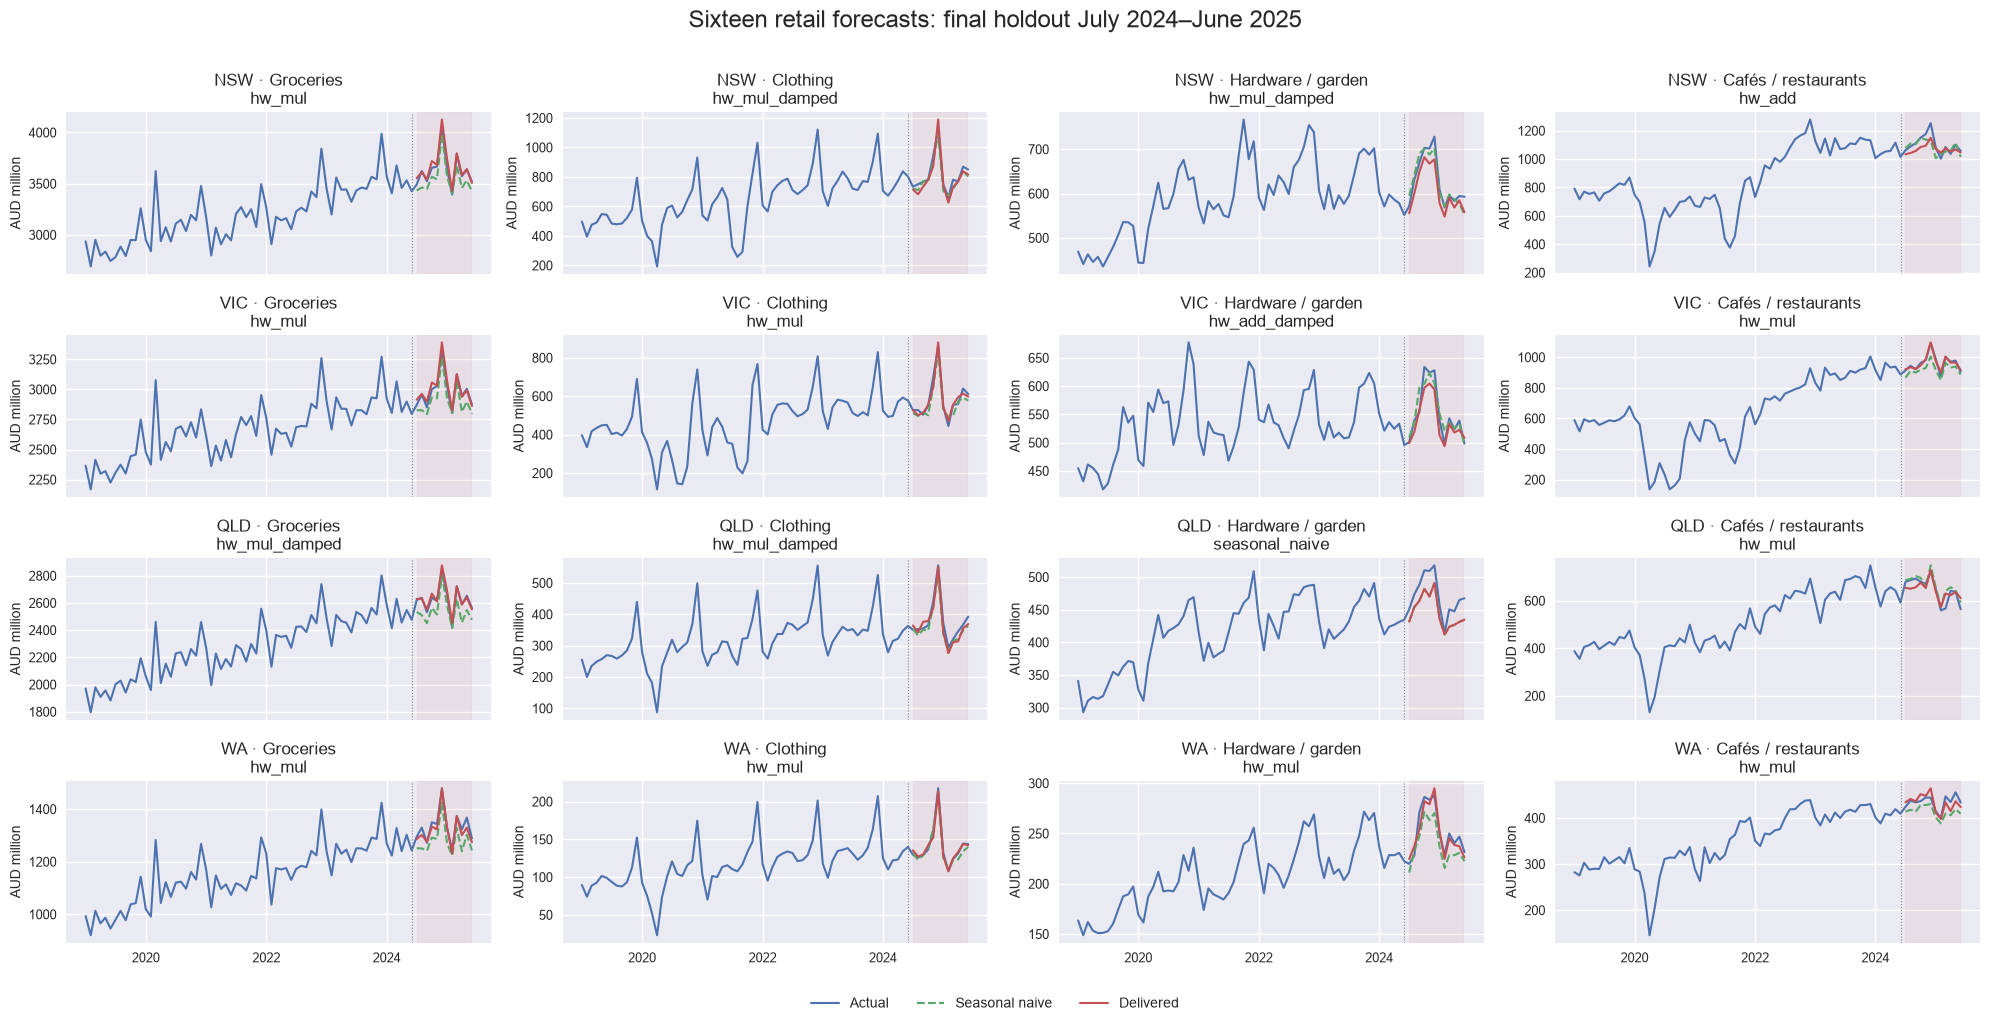

In [10]:
fig, axes = plt.subplots(4, 4, sharex=True)
for i, state in enumerate(states):
    for j, industry in enumerate(industries):
        ax = axes[i, j]
        part = panel[(panel.state == state) & (panel.industry == industry) & (panel.date >= "2019-01-01")]
        sid = part.series_id.iloc[0]
        row = next(r for r in record["rows"] if r["series_id"] == sid)
        dates = pd.to_datetime(row["delivery"]["dates"])
        ax.plot(part.date, part.turnover_aud_millions, color="C0", linewidth=1.5, label="Actual")
        ax.plot(dates, row["delivery"]["baseline"], color="C1", linewidth=1.5, linestyle="--", label="Seasonal naive")
        ax.plot(dates, row["delivery"]["forecast"], color="C2", linewidth=1.5, label="Delivered")
        ax.axvline(pd.Timestamp("2024-06-01"), color="0.5", linewidth=0.8, linestyle=":")
        ax.axvspan(pd.Timestamp("2024-07-01"), pd.Timestamp("2025-06-01"), color="C2", alpha=0.08)
        ax.set_title(f"{CFG.short_states[state]} · {CFG.short_industries[j]}\n{row['delivery']['delivered']}", fontsize=12)
        ax.set_ylabel("AUD million", fontsize=10)
        ax.tick_params(labelsize=9)
        ax.xaxis.set_major_locator(mdates.YearLocator(2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Sixteen retail forecasts: final holdout July 2024–June 2025", fontsize=17, y=1.01)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_asset(fig, "graph", 2, "Final forecasts, July 2024–June 2025")
plt.show()

This code generates a grid of time series plots displaying actual data, baseline forecasts (seasonal naive), and delivered forecasts for different combinations of Australian states and industries, focusing on the final holdout period.

It begins by creating a 4x4 grid of subplots using `plt.subplots(4, 4, sharex=True)`. The x-axis is shared across all subplots.

The code then iterates through each combination of state and industry:
*   For each combination, it filters the `panel` DataFrame to select data from 2019 onwards for that specific state and industry. It retrieves the `series_id` of the first row in this filtered subset.
*   It searches the `record["rows"]` list (containing results from the experiment) for a row matching the retrieved `series_id`. This row contains the forecasts and baseline predictions for that series.
*   The dates corresponding to the forecast horizon are extracted as datetime objects from `row["delivery"]["dates"]`.
*   Three lines are plotted on each subplot:
    *   Actual turnover data (`part.turnover_aud_millions`) in color C0, with a solid line and linewidth 1.5.
    *   The seasonal naive baseline forecast (`row["delivery"]["baseline"]`) in color C1, with a dashed line and linewidth 1.5.
    *   The delivered forecast (`row["delivery"]["forecast"]`) in color C2, with a solid line and linewidth 1.5.
*   A vertical line is added at "2024-06-01" to mark the end of the training data and the beginning of the holdout period.
*   A shaded region is added from "2024-07-01" to "2025-06-01" in color C2 with 8% transparency, representing the forecast horizon.
*   Each subplot’s title includes the abbreviated state and industry names (using `CFG.short_states` and `CFG.short_industries`), as well as the delivered model name from `row['delivery']['delivered']`. The font size is set to 12.
*   The y-axis label "AUD million" is added with a font size of 10, and tick labels are adjusted to a font size of 9.
*   X-axis major locators are set to yearly intervals, and the date format is set to "%Y".

A suptitle ("Sixteen retail forecasts: final holdout July 2024–June 2025") is added to the figure with a font size of 17. A legend is created using the handles and labels from the first subplot (`axes[0, 0]`) and placed at the bottom center of the figure with three columns and no frame.

`fig.tight_layout()` adjusts subplot parameters for better spacing, taking into account space for the suptitle. The `save_asset` function is called to save the combined plot as a PNG image titled "Final forecasts, July 2024–June 2025". Finally, `plt.show()` displays the figure in the notebook.


# Evaluate the portfolio results

**Table 6: Per-series forecast comparison for publication** — `graphs/atsf01-table6.png`

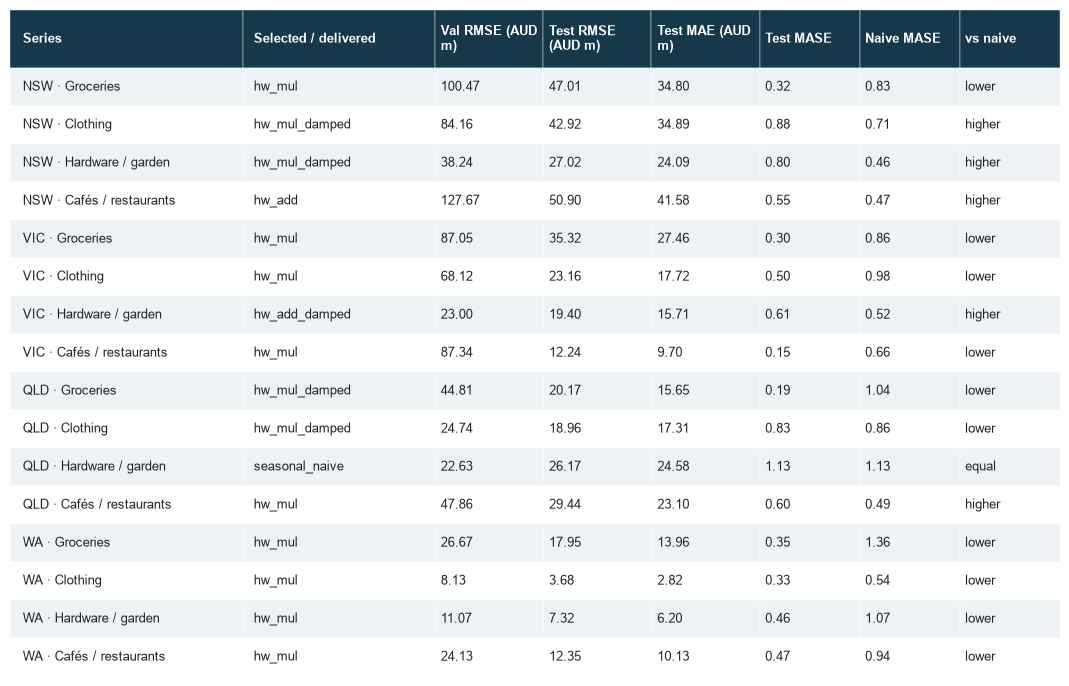

In [11]:
display_table = table.copy()
display_table["Series"] = [CFG.short_states[s] + " · " + CFG.short_industries[industries.index(i)] for s, i in zip(table.state, table.industry)]
columns = ["Series", "selected", "validation_rmse", "rmse", "mae", "mase", "baseline_mase", "comparison"]
shown = display_table[columns].copy()
shown["selected"] = [s if s == d else s + " → " + d for s, d in zip(table.selected, table.delivered)]
shown = shown.rename(columns={"selected": "Selected / delivered", "validation_rmse": "Val RMSE (AUD m)",
                              "rmse": "Test RMSE (AUD m)", "mae": "Test MAE (AUD m)",
                              "mase": "Test MASE", "baseline_mase": "Naive MASE", "comparison": "vs naive"})
save_table(shown, 6, "Per-series forecast comparison for publication",
           widths=[28, 23, 13, 13, 13, 12, 12, 12], show=True)

# Freeze the evidence / define the workflow

In [12]:
capture = load_capture(CFG.capture_file)
evidence = build_evidence(experiment)
before_reporting = (experiment.fingerprint, evidence.fingerprint)
display({key: value for key, value in evidence.data.items() if key.startswith("portfolio.")})
print("Evidence facts:", len(evidence.data))
print("Evidence IDs are citations, not a guarantee that a sentence is true.")

{'portfolio.delivered_model_counts': {'hw_add': 1,
  'hw_add_damped': 1,
  'hw_mul': 9,
  'hw_mul_damped': 4,
  'seasonal_naive': 1},
 'portfolio.fallback_count': 0,
 'portfolio.final_comparison': {'baseline_macro_mase': 0.8063839633715423,
  'delivered_macro_mase': 0.5301732997233599,
  'direction': 'lower',
  'losses': 5,
  'ties': 1,
  'wins': 10},
 'portfolio.review_series': ['A3349479C', 'A3349399C', 'A3349477X'],
 'portfolio.selected_model_counts': {'hw_add': 1,
  'hw_add_damped': 1,
  'hw_mul': 9,
  'hw_mul_damped': 4,
  'seasonal_naive': 1}}

Evidence facts: 82
Evidence IDs are citations, not a guarantee that a sentence is true.


This code loads previously captured experiment data, builds supporting evidence from the completed experiment, and displays relevant portfolio-level information.

First, `load_capture(CFG.capture_file)` is called to load data from a JSON file specified by `CFG.capture_file`. This likely contains results or intermediate states from a previous run of the forecasting workflow. The loaded data is stored in the `capture` variable.

Next, `build_evidence(experiment)` is called to construct supporting evidence based on the completed experiment (`experiment`). The resulting `evidence` object presumably contains information that can be used to justify or explain the experiment’s results.  The fingerprints of both the experiment and the evidence are stored in the `before_reporting` tuple, likely for tracking and reproducibility purposes.

A dictionary comprehension is then used to filter the `evidence.data` dictionary and display only those key-value pairs where the key starts with "portfolio.". This displays portfolio-level metrics or summaries within the Jupyter notebook.

Finally, it prints the total number of facts contained in the evidence (`len(evidence.data)`) and a disclaimer stating that evidence IDs are citations and do not guarantee the truthfulness of any specific statement.


**Graph 3: One experiment, three reporting paths** — `graphs/atsf01-graph3.png`

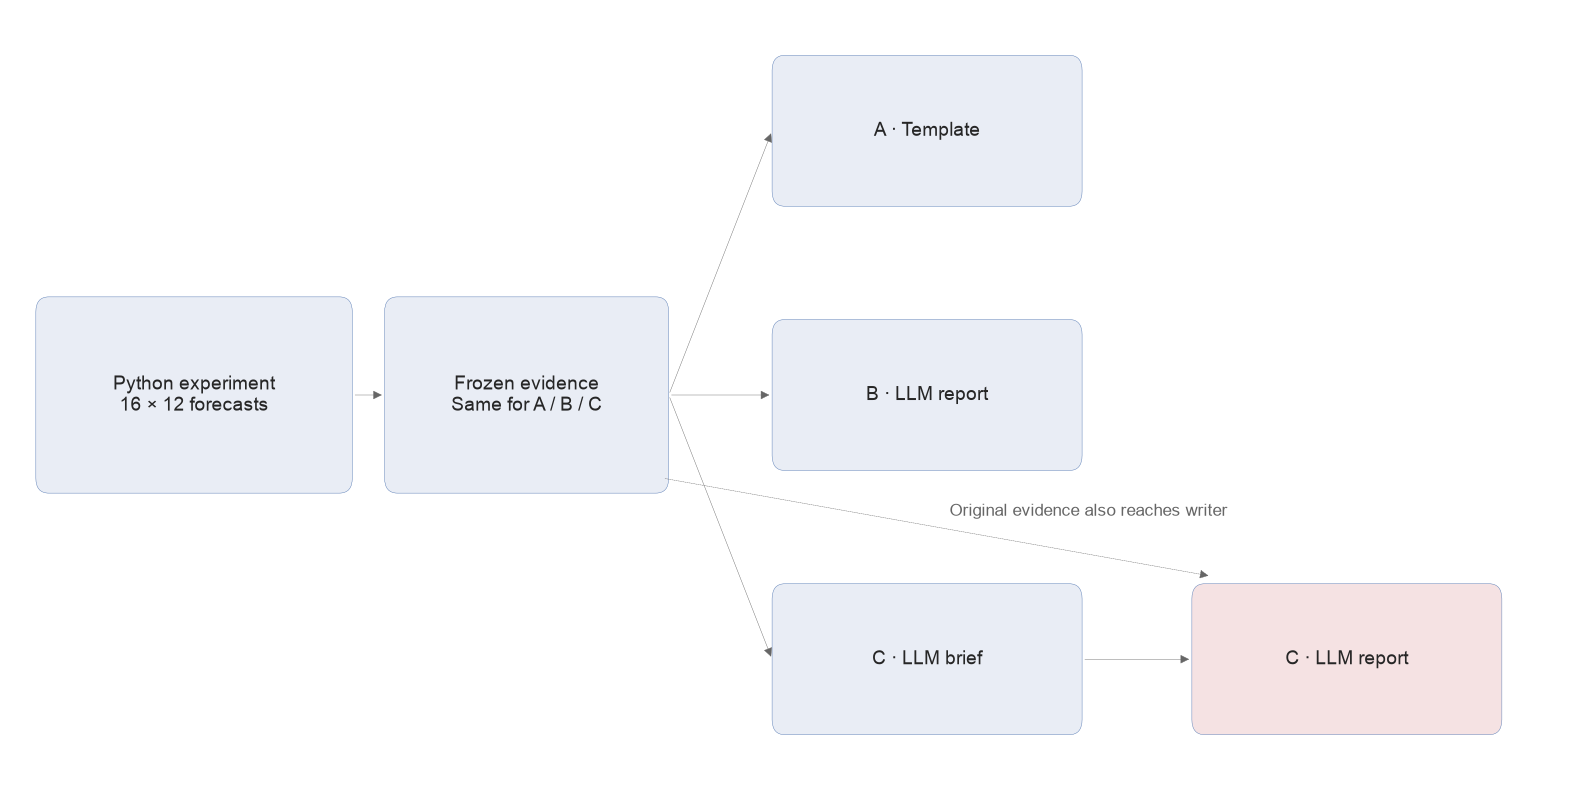

In [13]:
fig, ax = plt.subplots()
ax.set(xlim=(0, 12), ylim=(.5, 5.6))
ax.axis("off")
box(ax, .3, 2.5, 2.25, 1.1, "Python experiment\n16 × 12 forecasts")
box(ax, 3.0, 2.5, 2.0, 1.1, "Frozen evidence\nSame for A / B / C")
box(ax, 6.0, 4.4, 2.2, .8, "A · Template")
box(ax, 6.0, 2.65, 2.2, .8, "B · LLM report")
box(ax, 6.0, .9, 2.2, .8, "C · LLM brief")
box(ax, 9.25, .9, 2.2, .8, "C · LLM report", to_rgba("C2", .16))
arrow(ax, (2.65, 3.05), (2.9, 3.05))
for y in (4.8, 3.05, 1.3): arrow(ax, (5.1, 3.05), (5.9, y))
arrow(ax, (8.3, 1.3), (9.15, 1.3))
arrow(ax, (5.05, 2.5), (9.3, 1.85), dashed=True)
ax.text(8.35, 2.25, "Original evidence also reaches writer", ha="center", fontsize=12, color="0.4")
save_asset(fig, "graph", 3, "One experiment, three reporting paths")
plt.show()

This diagram illustrates the flow of information from an experiment to different reporting outputs generated by the LLM.
This is done with Matplotlib figure and axes object with fixed x and y limits, with axis display turned off  (`ax.axis("off")`).

The `box` function is used repeatedly to draw labeled rectangular boxes representing different components of the workflow:
*   A box for the "Python experiment" generating 16x12 forecasts.
*   A box for "Frozen evidence," indicating that the evidence remains consistent across different reporting paths (A, B, C).
*   Three boxes representing three different reporting outputs: “A · Template”, “B · LLM report”, and “C · LLM brief”. One instance of “C · LLM report” is filled with a light color ("C2" with alpha 0.16) to visually distinguish it.

The `arrow` function is used to draw arrows connecting these boxes, representing the flow of information:
*   An arrow from the "Python experiment" box to the "Frozen evidence" box.
*   Three arrows from the “Frozen evidence” box to each of the reporting output boxes (A, B, C).
*   An arrow from the second instance of “C · LLM report” back towards the frozen evidence.
*   A dashed arrow connecting the Python experiment directly to the second "C · LLM report" box.

Text is added to explain the dashed arrow: "Original evidence also reaches writer".

Finally, `save_asset` saves the diagram as a PNG image titled “One experiment, three reporting paths”, and `plt.show()` displays it in the notebook.

# Define the reporting contract

## A: deterministic template


In [14]:
arm_a = render_report("A", evidence)
display(Markdown(report_markdown(arm_a)))

**Arm A — template / ok**

**Selection.** Per-series selection minimizes mean RMSE across three validation folds. Selected models: hw_add: 1, hw_add_damped: 1, hw_mul: 9, hw_mul_damped: 4, seasonal_naive: 1.

Sources: `protocol.selection_rule`, `portfolio.selected_model_counts`

**Final evaluation.** On July 2024–June 2025, macro MASE is 0.5302, lower than seasonal naive (0.8064); Wins/ties/losses: 10/1/5. Final-refit fallbacks: 0.

Sources: `protocol.final_holdout`, `portfolio.final_comparison`, `portfolio.fallback_count`

**A3349479C.** Queensland, Hardware, building and garden supplies retailing: delivered MASE 1.1319, equal to the same-holdout baseline (1.1319). Delivered seasonal_naive; status ok.

Sources: `data.panel_manifest`, `series.A3349479C.evaluation`, `series.A3349479C.delivery`

**A3349399C.** New South Wales, Clothing retailing: delivered MASE 0.8775, higher than the same-holdout baseline (0.7063). Delivered hw_mul_damped; status ok.

Sources: `data.panel_manifest`, `series.A3349399C.evaluation`, `series.A3349399C.delivery`

**A3349477X.** Queensland, Clothing retailing: delivered MASE 0.8284, lower than the same-holdout baseline (0.8617). Delivered hw_mul_damped; status ok.

Sources: `data.panel_manifest`, `series.A3349477X.evaluation`, `series.A3349477X.delivery`

**Limitation.** The panel covers four states and four industries, with one final holdout. It cannot establish performance across all Australian retail.

Sources: `limitations.panel_scope`

This code renders a report using a specific template ("A") based on the previously built `evidence` and displays it as Markdown in the Jupyter notebook.

First, `render_report("A", evidence)` is called to generate a report. This function likely takes the template identifier "A" and the `evidence` object as input and produces a formatted report string or data structure. The result of this rendering process is stored in the `arm_a` variable.

Then, `report_markdown(arm_a)` is called to convert the rendered report (`arm_a`) into Markdown format. This function likely transforms any internal representation of the report into a standard Markdown string suitable for display in a Jupyter notebook.

Finally, `display(Markdown(...))` displays the resulting Markdown string within the notebook, rendering it as formatted text with headings, lists, and other Markdown elements.

## B: single-call LLM report

In [15]:
arm_b = render_report("B", evidence, mode=CFG.run_mode, config=CFG.llm, recorded=capture)
display(Markdown(report_markdown(arm_b)))

**Arm B — replay / ok**

**Selection.** Selected mix: hw_mul (9), hw_mul_damped (4), hw_add (1), hw_add_damped (1), seasonal_naive (1). Models chosen by minimum mean validation RMSE across three folds.

Sources: `portfolio.selected_model_counts`, `protocol.selection_rule`

**Final evaluation.** Final macro MASE was 0.5302, below the seasonal-naive baseline of 0.8064, indicating overall improvement. The delivered mix won 10 series, tied 1, and lost 5.

Sources: `portfolio.final_comparison`

**A3349479C.** Queensland hardware retail (A3349479C) delivered MASE 1.1319, equal to baseline MAE; selected seasonal_naive due to lowest validation RMSE.

Sources: `series.A3349479C.evaluation`, `series.A3349479C.selection`

**A3349399C.** New South Wales clothing retail (A3349399C) delivered MASE 0.8775, worse than baseline 0.7063; selected hw_mul_damped by validation RMSE.

Sources: `series.A3349399C.evaluation`, `series.A3349399C.selection`

**A3349477X.** Queensland clothing retail (A3349477X) delivered MASE 0.8284, better than baseline 0.8617; selected hw_mul_damped by validation RMSE.

Sources: `series.A3349477X.evaluation`, `series.A3349477X.selection`

**Limitation.** Only four states and four industries are covered; results do not generalize to all Australian retail or to unit-level demand.

Sources: `limitations.panel_scope`

This code renders a report using template "B" based on the `evidence`, runtime configuration, and potentially previously captured data, then displays it as Markdown in the Jupyter notebook.

`render_report("B", evidence, mode=CFG.run_mode, config=CFG.llm, recorded=capture)` is called to generate a report using template "B". This function receives:
*   `evidence`: The previously built evidence object.
*   `mode`: Set to `CFG.run_mode`, indicating whether the workflow is running in “live” or “replay” mode.
*   `config`: Set to `CFG.llm`, providing configuration details for the LLM used during report generation.
*   `recorded`: Set to `capture`, passing previously captured data from a previous run.

The result of this rendering process is stored in the `arm_b` variable.

Then, `report_markdown(arm_b)` converts the rendered report (`arm_b`) into Markdown format. Finally, `display(Markdown(...))` displays the resulting Markdown string within the notebook, rendering it as formatted text.

## C: evidence brief → report


In [16]:
arm_c = render_report("C", evidence, mode=CFG.run_mode, config=CFG.llm, recorded=capture)
display(Markdown("**Intermediate evidence brief**"))
display(arm_c["brief"])
display(Markdown(report_markdown(arm_c)))

**Intermediate evidence brief**

{'findings': [{'evidence_ids': ['portfolio.final_comparison'],
   'text': 'The final portfolio delivered a macro MASE of 0.5302, lower than the baseline macro MASE of 0.8064.'},
  {'evidence_ids': ['portfolio.final_comparison', 'portfolio.fallback_count'],
   'text': 'The final holdout (July 2024–June 2025) showed 10 wins, 1 tie, and 5 losses for the delivered model over the same-holdout baseline; no fallbacks were used.'},
  {'evidence_ids': ['models.catalog', 'portfolio.delivered_model_counts'],
   'text': 'The selected model mix used 9 hw_mul, 4 hw_mul_damped, 1 hw_add, 1 hw_add_damped, and 1 seasonal_naive across 16 series.'}],
 'limitations': [{'evidence_ids': ['limitations.fixed_vintage',
    'limitations.panel_scope'],
   'text': 'Results rely on a single June 2025 vintage and cover only four states and four industries, not all Australian retail.'},
  {'evidence_ids': ['limitations.nominal_turnover'],
   'text': 'Data represent nominal AUD turnover, not inflation-adjusted sales 

**Arm C — replay / ok**

**Selection.** Selected model mix: 9 hw_mul, 4 hw_mul_damped, 1 hw_add, 1 hw_add_damped, 1 seasonal_naive. Selection used per-series minimum validation RMSE.

Sources: `portfolio.selected_model_counts`, `protocol.selection_rule`

**Final evaluation.** Final macro MASE was 0.5302, lower than the seasonal-naive baseline macro MASE of 0.8064.

Sources: `portfolio.final_comparison`

**A3349479C.** Series A3349479C (Hardware, building and garden supplies retailing, Queensland) delivered seasonal_naive with MASE 1.1319, equal to its baseline MAE.

Sources: `series.A3349479C.evaluation`, `series.A3349479C.selection`

**A3349399C.** Series A3349399C (Clothing retailing, New South Wales) selected hw_mul_damped (validation RMSE 84.1616) but delivered MASE 0.8775, higher than its baseline MASE 0.7063.

Sources: `series.A3349399C.evaluation`, `series.A3349399C.selection`

**A3349477X.** Series A3349477X (Clothing retailing, Queensland) selected hw_mul_damped (validation RMSE 24.7443) and delivered MASE 0.8284, lower than its baseline MASE 0.8617.

Sources: `series.A3349477X.evaluation`, `series.A3349477X.selection`

**Limitation.** Coverage is limited to four states and four industries; not representative of all Australian retail.

Sources: `limitations.panel_scope`

This code renders a report using template "C", incorporating the `evidence`, runtime configuration, and potentially previously captured data. It then displays an intermediate “brief” section of the report followed by the full rendered Markdown version.

First, `render_report("C", evidence, mode=CFG.run_mode, config=CFG.llm, recorded=capture)` is called to generate a report using template "C". This call includes several additional parameters:
*   `evidence`: The previously built evidence object.
*   `mode`: Set to `CFG.run_mode`, indicating whether the workflow is running in “live” or “replay” mode, potentially influencing how the report is generated.
*   `config`: Set to `CFG.llm`, providing configuration details for the LLM used during report generation (model URL, temperature, etc.).
*   `recorded`: Set to `capture`, passing previously captured data from a previous run, which might be used for context or comparison.

The result of this rendering process is stored in the `arm_c` variable.

Next, it displays a Markdown heading “Intermediate evidence brief”. Then, it displays the content of the "brief" key within the `arm_c` object using `display(arm_c["brief"])`. This suggests that template "C" generates a concise summary or abstract as part of its output.

Finally, it converts the full rendered report (`arm_c`) to Markdown format using `report_markdown()` and displays it in the notebook using `display(Markdown(...))`.

# Review the generated reports

In [17]:
# Side-by-side prose; the shared numerical table above supplies complete coverage.
reports = [arm_a, arm_b, arm_c]
blocks = []
for result in reports:
    report = result["report"]
    claims = [report["selection"], report["evaluation"]] + [x["claim"] for x in report["review_series"]] + [report["limitation"]]
    body = "".join("<p>" + escape(table_text(c["text"])) + "</p>" for c in claims)
    blocks.append(f"<td style='vertical-align:top;width:33%;padding:12px;border:1px solid #ccd5db'><b>{escape(result['arm'])}: {escape(result['mode'])} / {escape(result['status'])}</b>{body}</td>")
display(HTML("<table style='width:100%'><tr>" + "".join(blocks) + "</tr></table>"))
assert before_reporting == (experiment.fingerprint, evidence.fingerprint)

# Only the displayed decimal precision changes; captured responses and semantic errors are retained.
sections = ["Selection", "Final evaluation", "Review series 1", "Review series 2", "Review series 3", "Limitation"]
comparison_table = pd.DataFrame({"Section": sections})
for result in reports:
    report = result["report"]
    claims = [report["selection"], report["evaluation"]] + [x["claim"] for x in report["review_series"]] + [report["limitation"]]
    comparison_table[f"{result['arm']}: {result['mode']} / {result['status']}"] = [table_text(c["text"]) for c in claims]
save_table(comparison_table, 7, "Three reporting paths: actual report text", widths=[18, 58, 58, 58])


"A: template / okPer-series selection minimizes mean RMSE across three validation folds. Selected models: hw_add: 1, hw_add_damped: 1, hw_mul: 9, hw_mul_damped: 4, seasonal_naive: 1.On July 2024–June 2025, macro MASE is 0.53, lower than seasonal naive (0.81); Wins/ties/losses: 10/1/5. Final-refit fallbacks: 0.Queensland, Hardware, building and garden supplies retailing: delivered MASE 1.13, equal to the same-holdout baseline (1.13). Delivered seasonal_naive; status ok.New South Wales, Clothing retailing: delivered MASE 0.88, higher than the same-holdout baseline (0.71). Delivered hw_mul_damped; status ok.Queensland, Clothing retailing: delivered MASE 0.83, lower than the same-holdout baseline (0.86). Delivered hw_mul_damped; status ok.The panel covers four states and four industries, with one final holdout. It cannot establish performance across all Australian retail.","B: replay / okSelected mix: hw_mul (9), hw_mul_damped (4), hw_add (1), hw_add_damped (1), seasonal_naive (1). Models chosen by minimum mean validation RMSE across three folds.Final macro MASE was 0.53, below the seasonal-naive baseline of 0.81, indicating overall improvement. The delivered mix won 10 series, tied 1, and lost 5.Queensland hardware retail (A3349479C) delivered MASE 1.13, equal to baseline MAE; selected seasonal_naive due to lowest validation RMSE.New South Wales clothing retail (A3349399C) delivered MASE 0.88, worse than baseline 0.71; selected hw_mul_damped by validation RMSE.Queensland clothing retail (A3349477X) delivered MASE 0.83, better than baseline 0.86; selected hw_mul_damped by validation RMSE.Only four states and four industries are covered; results do not generalize to all Australian retail or to unit-level demand.","C: replay / okSelected model mix: 9 hw_mul, 4 hw_mul_damped, 1 hw_add, 1 hw_add_damped, 1 seasonal_naive. Selection used per-series minimum validation RMSE.Final macro MASE was 0.53, lower than the seasonal-naive baseline macro MASE of 0.81.Series A3349479C (Hardware, building and garden supplies retailing, Queensland) delivered seasonal_naive with MASE 1.13, equal to its baseline MAE.Series A3349399C (Clothing retailing, New South Wales) selected hw_mul_damped (validation RMSE 84.16) but delivered MASE 0.88, higher than its baseline MASE 0.71.Series A3349477X (Clothing retailing, Queensland) selected hw_mul_damped (validation RMSE 24.74) and delivered MASE 0.83, lower than its baseline MASE 0.86.Coverage is limited to four states and four industries; not representative of all Australian retail."


**Table 7: Three reporting paths: actual report text** — `graphs/atsf01-table7.png`

This code compares the textual content of reports generated by different templates (A, B, and C) side-by-side, presenting them in an HTML table. It also creates a Pandas DataFrame for more structured comparison.

First, it initializes an empty list called `blocks` to store HTML table cells representing each report. It then iterates through the `reports` list (containing `arm_a`, `arm_b`, and `arm_c`). For each report:
*   It extracts the "report" dictionary from the result.
*   It collects key claims from the report, including “selection”, “evaluation”, review series claims, and a limitation statement.
*   It joins these claims into an HTML string, wrapping each claim's text in `<p>` tags after escaping any HTML characters using `escape()` and rounding decimal numbers using `table_text()`.
*   An HTML table cell (`<td>`) is created containing the report’s arm name, mode, status, and the combined HTML body. This cell is appended to the `blocks` list.

Finally, an HTML table is constructed by joining the cells in `blocks` into a row (`<tr>`) within a table tag (`<table>`). The resulting HTML string is displayed in the notebook using `display(HTML(...))`, creating a side-by-side comparison of the reports’ textual content.

An assertion verifies that the experiment and evidence fingerprints have not changed since before reporting, ensuring reproducibility.

Next, it creates a Pandas DataFrame called `comparison_table` to provide a more structured comparison:
*   The "Section" column is initialized with the names of key sections within each report ("Selection", "Final evaluation", etc.).
*   It iterates through the reports again and extracts the text from each claim in each section, using `table_text()` for consistent decimal formatting. These texts are added as new columns to the `comparison_table`, named after the corresponding report’s arm name, mode, and status.

Finally, it saves this comparison table as an image using `save_table`, titled “Three reporting paths: actual report text”.

In [18]:
audit_table = pd.DataFrame([
    {"check": "Strict response contract", "A": "pass", "B capture": "pass", "C capture": "pass"},
    {"check": "MASE / MAE wording", "A": "pass", "B capture": "fail", "C capture": "fail"},
    {"check": "Required win/tie/loss counts", "A": "pass", "B capture": "pass", "C capture": "omitted"},
    {"check": "Independent human review", "A": "pending", "B capture": "pending", "C capture": "pending"},
])
display(audit_table)
save_table(audit_table, 9, "Structural checks and semantic review", widths=[35, 15, 18, 18])

,check,A,B capture,C capture
0,Strict response contract,pass,pass,pass
1,MASE / MAE wording,pass,fail,fail
2,Required win/tie/loss counts,pass,pass,omitted
3,Independent human review,pending,pending,pending


**Table 9: Structural checks and semantic review** — `graphs/atsf01-table9.png`

This code creates and displays a table summarizing the results of an audit performed on the generated reports.

A Pandas DataFrame called `audit_table` is created with four rows representing different structural and semantic checks:
*   “Strict response contract” – verifying adherence to predefined output formats.
*   “MASE / MAE wording” – checking for correct terminology in describing model performance metrics.
*   “Required win/tie/loss counts” – ensuring that reports include the expected number of comparisons between models.
*   “Independent human review” – indicating whether a human reviewer has assessed the report’s quality and accuracy.

Each row includes columns for “A”, “B capture”, and “C capture”, representing the results of the check for each reporting template (A, B) and captured versions of templates B and C. The values in these columns indicate whether the check passed ("pass"), failed ("fail"), was omitted (“omitted”), or is still pending review ("pending").

The `audit_table` is displayed in the notebook using `display(audit_table)`. It’s then saved as an image using `save_table`, titled “Structural checks and semantic review”, with specified column widths.

# Inspect timing and token usage

In [18]:
trace = []
for result in reports:
    for stage in result["stages"]:
        response = stage.get("response", {})
        trace.append({"arm": result["arm"], "mode": result["mode"], "stage": stage["kind"], "status": stage["status"],
                      "this_execution_seconds": stage["seconds"], "archived_live_seconds": stage.get("observed_live_seconds"),
                      "prompt_tokens": response.get("usage", {}).get("prompt_eval_count"),
                      "output_tokens": response.get("usage", {}).get("eval_count"),
                      "server_load_seconds": response.get("metadata", {}).get("load_duration", 0) / 1e9})
trace_table = pd.DataFrame(trace)
display(trace_table)
save_table(trace_table, 8, "Reporting-stage trace and recorded inference timing", widths=[8, 12, 12, 10, 18, 18, 14, 14, 18])


,arm,mode,stage,status,this_execution_seconds,archived_live_seconds,prompt_tokens,output_tokens,server_load_seconds
0,B,replay,report,ok,0.00,34.58,6356,540,19.47
1,C,replay,brief,ok,0.00,16.62,6313,681,0.00
2,C,replay,report,ok,0.00,10.44,6947,544,0.00


**Table 8: Reporting-stage trace and recorded inference timing** — `graphs/atsf01-table8.png`

This code generates a detailed trace of the execution time and resource usage for each stage involved in generating the reports.

It initializes an empty list called `trace` to store information about each reporting stage. It then iterates through the `reports` list (containing `arm_a`, `arm_b`, and `arm_c`). For each report:
*   It iterates through the "stages" within that report.
*   For each stage, it extracts relevant data from the `stage` dictionary:
    *   `kind`: The type of reporting stage (e.g., prompt generation, LLM call).
    *   `status`: The status of the stage (e.g., "ok", "error").
    *   `seconds`: The execution time of the stage in seconds.
    *   `observed_live_seconds`: Execution time from a live run if available.
    *   `prompt_eval_count`: Number of prompt tokens used.
    *   `eval_count`: Number of output tokens generated.
    *   `load_duration`: Server load duration in seconds (converted to seconds by dividing by 1e9).

*   This information is packaged into a dictionary and appended to the `trace` list.

After processing all reports and stages, it creates a Pandas DataFrame called `trace_table` from the collected data. The `trace_table` is displayed in the notebook using `display(trace_table)`. It’s then saved as an image using `save_table`, titled “Reporting-stage trace and recorded inference timing”, with specified column widths.

In summary, this code provides a detailed performance profile of each stage involved in generating the reports, including execution time, token usage, and server load. This information can be used to identify bottlenecks and optimize the reporting workflow. The inclusion of both current execution times and archived live run times allows for comparison between different environments or configurations.

# Test failure handling

In [19]:
injected = inject_unknown_reference(evidence)
assert injected["status"] == "fallback"
display(Markdown(report_markdown(injected)))
assert before_reporting == (experiment.fingerprint, evidence.fingerprint)
print("Numerical experiment and evidence are unchanged after every reporting arm.")

assert sorted(a["number"] for a in exported_assets if a["kind"] == "graph") == [1, 2, 3]
assert sorted(a["number"] for a in exported_assets if a["kind"] == "table") == list(range(1, 10))
assert all((CFG.graph_folder / a["file"]).is_file() for a in exported_assets)
print("Saved all 3 graphs and 9 tables in graphs/ using atsf01 names.")


**Arm B — injected / fallback**

Template fallback: ValueError: Unknown or empty evidence references

**Selection.** Per-series selection minimizes mean RMSE across three validation folds. Selected models: hw_add: 1, hw_add_damped: 1, hw_mul: 9, hw_mul_damped: 4, seasonal_naive: 1.

Sources: `protocol.selection_rule`, `portfolio.selected_model_counts`

**Final evaluation.** On July 2024–June 2025, macro MASE is 0.5302, lower than seasonal naive (0.8064); Wins/ties/losses: 10/1/5. Final-refit fallbacks: 0.

Sources: `protocol.final_holdout`, `portfolio.final_comparison`, `portfolio.fallback_count`

**A3349479C.** Queensland, Hardware, building and garden supplies retailing: delivered MASE 1.1319, equal to the same-holdout baseline (1.1319). Delivered seasonal_naive; status ok.

Sources: `data.panel_manifest`, `series.A3349479C.evaluation`, `series.A3349479C.delivery`

**A3349399C.** New South Wales, Clothing retailing: delivered MASE 0.8775, higher than the same-holdout baseline (0.7063). Delivered hw_mul_damped; status ok.

Sources: `data.panel_manifest`, `series.A3349399C.evaluation`, `series.A3349399C.delivery`

**A3349477X.** Queensland, Clothing retailing: delivered MASE 0.8284, lower than the same-holdout baseline (0.8617). Delivered hw_mul_damped; status ok.

Sources: `data.panel_manifest`, `series.A3349477X.evaluation`, `series.A3349477X.delivery`

**Limitation.** The panel covers four states and four industries, with one final holdout. It cannot establish performance across all Australian retail.

Sources: `limitations.panel_scope`

Numerical experiment and evidence are unchanged after every reporting arm.
Saved all 3 graphs and 9 tables in graphs/ using atsf01 names.


This code performs a final check on the reporting process, verifies data integrity, and confirms that all expected assets have been saved.

First, `inject_unknown_reference(evidence)` is called to simulate handling an unknown reference within the evidence. The result is stored in the `injected` variable. An assertion checks that the status of this operation is "fallback", indicating that a default behavior was triggered when encountering the unknown reference. The resulting report from this injection is then displayed as Markdown using `report_markdown()`.

Another assertion verifies that the experiment and evidence fingerprints remain unchanged after all reporting arms have been executed, reinforcing data integrity and reproducibility. A message confirming this is printed to the console.

Finally, a series of assertions are used to validate the saved assets:
*   It checks that the graph asset numbers are sorted as [1, 2, 3].
*   It verifies that the table asset numbers range from 1 to 9.
*   It confirms that all files listed in `exported_assets` actually exist within the `CFG.graph_folder`.

A message is printed to the console confirming that all expected graphs and tables have been saved with the specified naming convention ("atsf01") in the "graphs" folder.